# k-means 클러스터링 실습

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/SuminHan/book-ml/blob/main/slides/v2/ml1/week04/kmeans/lab/kmeans.ipynb)

할당(가장 가까운 중심) 과 갱신(평균으로) 의 반복. 직접 구현하고, 라벨 없이 펭귄을 무리로 나눠 본다.

- **파트 1**: k-means 직접 구현 → 슬라이드의 SSE 269 → 29, 나쁜 시작 127 재현
- **파트 2**: 펭귄 333마리를 종 라벨 없이 3무리로 → 진짜 종과 비교, 표준화 전후
- **파트 3**: 엘보우로 k 고르기

`None` 으로 비워 둔 `TODO` 줄을 채우고 셀을 차례로 실행하세요.

In [ ]:
import os
import numpy as np
import matplotlib.pyplot as plt

## 슬라이드의 예시 데이터

지도 위 집 30곳 (0~10 눈금).

In [ ]:
# Same example as the slides: 30 houses on a 10 x 10 map
X = np.array([[2.5, 7.5], [2.3, 6.4], [2.1, 6.4], [2.6, 8.3], [2.1, 6.7], [2.9, 7.5], [2.6, 6.4], [2.5, 7.8], [1.4, 6.8], [0.9, 6.1],
              [5.8, 7.4], [6.3, 7.8], [7.5, 7.4], [5.3, 7.1], [7.4, 7.7], [6.1, 7.2], [6.6, 6.9], [8.3, 6.9], [7.4, 8.4], [6.9, 7.5],
              [5.1, 2.7], [4.0, 2.7], [6.2, 1.3], [5.7, 2.7], [4.5, 4.3], [5.6, 1.6], [5.1, 3.1], [4.8, 3.2], [4.9, 3.2], [6.2, 2.0]])
plt.scatter(X[:, 0], X[:, 1]); plt.gca().set_aspect("equal"); plt.show()

**예상 결과**

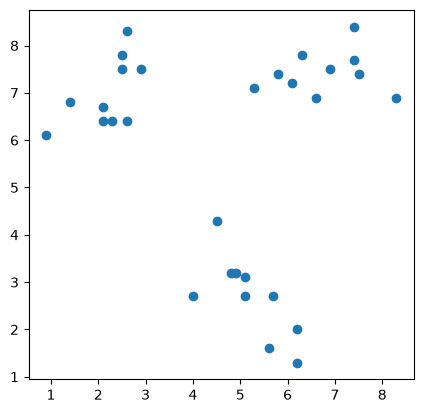

## 파트 1. 할당과 갱신

$$a(i) = \arg\min_j \lVert \mathbf{x}^{(i)} - \mathbf{c}_j \rVert, \qquad \mathbf{c}_j = \text{mean of the houses assigned to } j, \qquad \text{SSE} = \sum_i \lVert \mathbf{x}^{(i)} - \mathbf{c}_{a(i)} \rVert^2$$

In [ ]:
def assign(X, C):
    d2 = ((X[:, None, :] - C[None, :, :]) ** 2).sum(axis=2)   # squared distance, shape (houses, centers)
    return None  # TODO: index of the nearest center for each house

def update(X, labels, C):
    return None  # TODO: mean of each group

def sse(X, C, labels):
    return ((X - C[labels]) ** 2).sum()

def kmeans(X, init, max_iter=20):
    C = np.array(init, dtype=float)
    history = []
    for _ in range(max_iter):
        labels = assign(X, C)
        history.append(sse(X, C, labels))
        new_C = update(X, labels, C)
        if np.allclose(new_C, C):
            break
        C = new_C
    return C, labels, history

C, labels, hist = kmeans(X, [[1.5, 3.0], [4.5, 5.0], [8.5, 3.5]])
print("good start SSE:", np.round(hist).astype(int).tolist(), " sizes:", np.bincount(labels).tolist())
C_bad, labels_bad, hist_bad = kmeans(X, [[4.4, 3.0], [6.0, 2.2], [4.5, 8.6]])
print("bad start  SSE:", np.round(hist_bad).astype(int).tolist(), " sizes:", np.bincount(labels_bad).tolist())

fig, axs = plt.subplots(1, 2, figsize=(10, 4.5))
for ax, (c, l, t) in zip(axs, [(C, labels, "good start"), (C_bad, labels_bad, "bad start")]):
    ax.scatter(X[:, 0], X[:, 1], c=l, cmap="tab10", vmax=9); ax.scatter(c[:, 0], c[:, 1], marker="*", s=300, c="k"); ax.set_title(t)
plt.show()

**예상 결과**

```
good start SSE: [269, 134, 33, 29]  sizes: [10, 10, 10]
bad start  SSE: [167, 127]  sizes: [6, 4, 20]
```

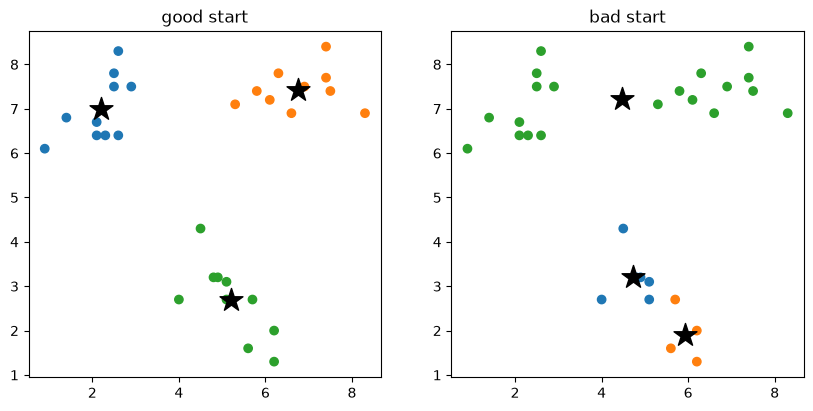

## 파트 2. 라벨 없이 펭귄 나누기

부리 길이(mm) 와 몸무게(g) 만 보고 3무리로 나눈 뒤, 그제서야 진짜 종과 비교한다. 두 특징의 크기가 얼마나 다른지 먼저 보자.

In [ ]:
import pandas as pd
from sklearn.cluster import KMeans
from sklearn.preprocessing import StandardScaler

url = "https://raw.githubusercontent.com/mwaskom/seaborn-data/master/penguins.csv"
os.makedirs("data", exist_ok=True)
if not os.path.exists("data/penguins.csv"):
    import urllib.request; urllib.request.urlretrieve(url, "data/penguins.csv")
df = pd.read_csv("data/penguins.csv").dropna()
F = df[["bill_length_mm", "body_mass_g"]].to_numpy(float)
print(len(df), "penguins"); print(df[["bill_length_mm", "body_mass_g"]].describe().loc[["mean", "std"]].round(1))

**예상 결과**

```
333 penguins
      bill_length_mm  body_mass_g
mean            44.0       4207.1
std              5.5        805.2
```

In [ ]:
def purity(true_labels, clusters):
    # for each cluster take its most common species; fraction of penguins that match
    t = pd.crosstab(clusters, true_labels)
    return t.max(axis=1).sum() / t.values.sum()

for name, Z in [("raw", F), ("standardized", StandardScaler().fit_transform(F))]:
    km = KMeans(n_clusters=3, n_init=10, random_state=0).fit(Z)
    print(f"{name:13s}: purity {purity(df['species'], km.labels_):.3f}")
    print(pd.crosstab(df["species"], km.labels_), "\n")

**예상 결과**

```
raw          : purity 0.679
col_0        0   1   2
species               
Adelie     108  38   0
Chinstrap   52  16   0
Gentoo       1  50  68 

standardized : purity 0.907
col_0       0    1    2
species                
Adelie      4    3  139
Chinstrap  61    1    6
Gentoo     14  102    3 
```

**관찰**: 표준화 전에는 어느 특징이 거리를 혼자 정했을까? 그 결과 무리가 어떻게 나뉘었나?

## 파트 3. 엘보우로 k 고르기

`KMeans(...).inertia_` 가 SSE 다.

In [ ]:
Z = StandardScaler().fit_transform(df[["bill_length_mm", "bill_depth_mm", "flipper_length_mm", "body_mass_g"]])
ks = range(1, 9)
inertia = None  # TODO: SSE for each k
plt.plot(ks, inertia, "o-"); plt.xlabel("k"); plt.ylabel("SSE (inertia)"); plt.show()
print([round(v) for v in inertia])

**예상 결과**

```
[1332, 553, 371, 294, 229, 200, 183, 167]
```

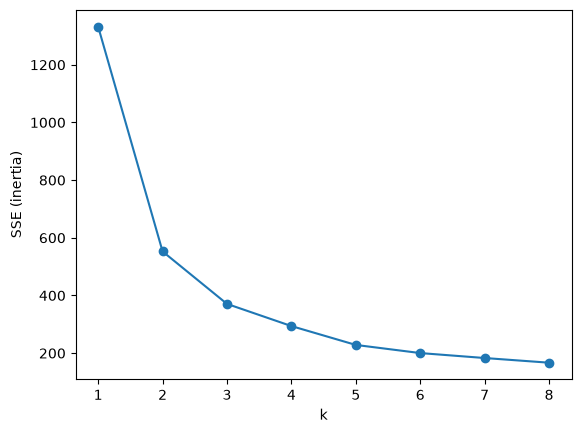

**확인 질문**
1. 파트 1 의 나쁜 시작에서 할당을 한 번 더 해도 바뀌지 않는 이유를 그림으로 설명해 보자.
2. 파트 2 에서 표준화 후 가장 많이 섞인 두 종은? 부리 길이와 몸무게만으로 구별이 어려운 이유는?
3. 파트 3 의 엘보우는 몇에서 꺾이는가? 진짜 종의 수(3) 와 같은가?
4. (도전) 파트 2 를 `KMeans(n_clusters=3, init="random", n_init=1, random_state=s)` 로 s 를 바꿔 가며 돌리면 SSE 가 매번 같은가?

데이터 출처: Gorman, Williams, Fraser (2014) PLoS ONE 9(3) · Palmer Station LTER, seaborn-data 사본.